In [5]:
# Import libraries for data handling
import pandas as pd
import numpy as np

# Import libraries for visualisation
import matplotlib.pyplot as plt

# Import statistical distributions
from scipy.stats import poisson, lognorm

# Import optimisation and numerical functions
from scipy.optimize import minimize
from scipy.special import logsumexp

# Import model evaluation tools
from sklearn.model_selection import train_test_split

print("All libraries imported successfully!")

All libraries imported successfully!


In [6]:
# Load the cleaned invoice-level dataset
invoices = pd.read_csv("data/final_invoice_level.csv")

# Display dataset dimensions
print("Dataset shape:", invoices.shape)

# Display column names
print("\nColumn names:")
print(invoices.columns.tolist())

# Display first five observations
display(invoices.head())

Dataset shape: (36594, 13)

Column names:
['InvoiceYear', 'InvoiceNo', 'CustomerID', 'Country', 'InvoiceDate', 'InvoiceMonth', 'InvoiceAmount', 'ItemQuantity', 'ProductLineCount', 'DistinctProducts', 'PossibleDuplicateLineCount', 'HighInvoiceAmountFlag', 'InvoiceTimestampSpreadMinutes']


,InvoiceYear,InvoiceNo,CustomerID,Country,InvoiceDate,InvoiceMonth,InvoiceAmount,ItemQuantity,ProductLineCount,DistinctProducts,PossibleDuplicateLineCount,HighInvoiceAmountFlag,InvoiceTimestampSpreadMinutes
0,2009,489434,13085,United Kingdom,2009-12-01 07:45:00,2009-12,505.30,166,8,8,0,False,0.0
1,2009,489435,13085,United Kingdom,2009-12-01 07:46:00,2009-12,145.80,60,4,4,0,False,0.0
2,2009,489436,13078,United Kingdom,2009-12-01 09:06:00,2009-12,630.33,193,19,19,0,False,0.0
3,2009,489437,15362,United Kingdom,2009-12-01 09:08:00,2009-12,310.75,145,23,23,0,False,0.0
4,2009,489438,18102,United Kingdom,2009-12-01 09:24:00,2009-12,2286.24,826,17,17,0,False,0.0


In [7]:
# Check important column data types
print("Data types:")
print(invoices[["CustomerID", "InvoiceNo", "InvoiceDate", "InvoiceAmount"]].dtypes)

# Check missing values
print("\nMissing values:")
print(invoices[["CustomerID", "InvoiceNo", "InvoiceDate", "InvoiceAmount"]].isnull().sum())

# Convert date and amount into appropriate formats
invoices["InvoiceDate"] = pd.to_datetime(invoices["InvoiceDate"])
invoices["InvoiceAmount"] = pd.to_numeric(invoices["InvoiceAmount"], errors="coerce")

# Display date range
print("\nFirst invoice date:", invoices["InvoiceDate"].min())
print("Last invoice date:", invoices["InvoiceDate"].max())

# Check negative and zero invoice amounts
print("\nNon-positive invoice amounts:",
      (invoices["InvoiceAmount"] <= 0).sum())

Data types:
CustomerID         int64
InvoiceNo          int64
InvoiceDate          str
InvoiceAmount    float64
dtype: object

Missing values:
CustomerID       0
InvoiceNo        0
InvoiceDate      0
InvoiceAmount    0
dtype: int64

First invoice date: 2009-12-01 07:45:00
Last invoice date: 2011-12-09 12:50:00

Non-positive invoice amounts: 0


In [8]:
# Select the common 24-month analysis period
analysis_invoices = invoices[
    (invoices["InvoiceDate"] >= "2009-12-01") &
    (invoices["InvoiceDate"] < "2011-12-01")
].copy()

# Check the selected analysis period
print("First invoice:", analysis_invoices["InvoiceDate"].min())
print("Last invoice:", analysis_invoices["InvoiceDate"].max())

# Check dataset dimensions
print("Dataset shape:", analysis_invoices.shape)

# Count unique customers and invoices
print("Unique customers:", analysis_invoices["CustomerID"].nunique())
print("Unique invoices:", analysis_invoices["InvoiceNo"].nunique())

First invoice: 2009-12-01 07:45:00
Last invoice: 2011-11-30 17:37:00
Dataset shape: (35818, 13)
Unique customers: 5824
Unique invoices: 35818


In [9]:
# Create customer-level purchasing information

customer_summary = analysis_invoices.groupby("CustomerID").agg(
    PurchaseCount=("InvoiceNo", "nunique"),
    TotalSpending=("InvoiceAmount", "sum"),
    AverageInvoiceAmount=("InvoiceAmount", "mean")
).reset_index()

# Display the first five customers
display(customer_summary.head())

# Check the number of customers
print("Total customers:", len(customer_summary))

# Display summary statistics
display(customer_summary[
    ["PurchaseCount", "TotalSpending", "AverageInvoiceAmount"]
].describe())

,CustomerID,PurchaseCount,TotalSpending,AverageInvoiceAmount
0,12346,3,77352.96,25784.320000
1,12347,7,5408.50,772.642857
2,12348,5,1658.40,331.680000
3,12349,3,3678.69,1226.230000
4,12350,1,294.40,294.400000


Total customers: 5824


,PurchaseCount,TotalSpending,AverageInvoiceAmount
count,5824.000000,5824.000000,5824.000000
mean,6.150069,2905.251425,376.611856
std,12.519748,14208.570276,609.916540
min,1.000000,2.900000,2.900000
25%,1.000000,340.482500,180.716250
50%,3.000000,866.580000,284.527000
75%,7.000000,2249.667500,419.754500
max,364.000000,597336.110000,25784.320000


,CustomerID,PurchaseCount,TotalSpending,AverageInvoiceAmount
0,12346,3,77352.96,25784.320000
3332,15749,3,44534.30,14844.766667
2689,15098,3,39916.50,13305.500000
1302,13687,1,11880.84,11880.840000
5588,18052,1,10877.18,10877.180000
234,12590,1,9341.26,9341.260000
11,12357,2,17437.66,8718.830000
1514,13902,5,34023.26,6804.652000
66,12415,24,144033.37,6001.390417
5002,17450,50,245410.69,4908.213800


Correlation matrix:


,PurchaseCount,AverageInvoiceAmount,TotalSpending
PurchaseCount,1.000000,0.077156,0.628384
AverageInvoiceAmount,0.077156,1.000000,0.303479
TotalSpending,0.628384,0.303479,1.000000


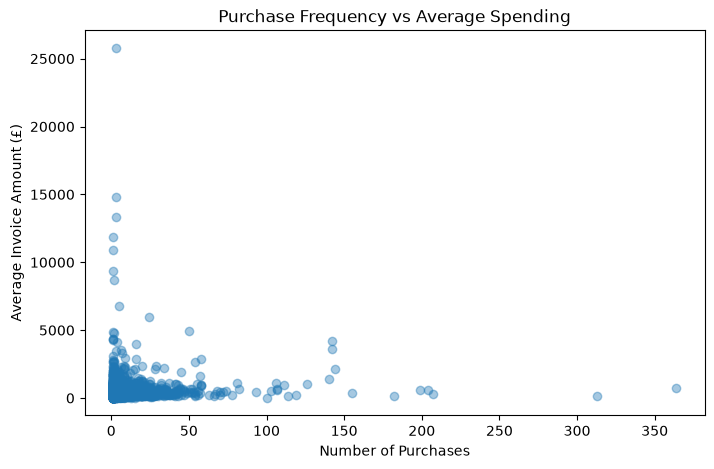

In [10]:
# Identify customers with the highest average invoice amounts

top_spenders = customer_summary.sort_values(
    by="AverageInvoiceAmount",
    ascending=False
).head(10)

display(top_spenders)

# Calculate correlation between purchase frequency and spending

correlation = customer_summary[
    ["PurchaseCount", "AverageInvoiceAmount", "TotalSpending"]
].corr()

print("Correlation matrix:")
display(correlation)

# Visualise the relationship between frequency and spending

plt.figure(figsize=(8, 5))

plt.scatter(
    customer_summary["PurchaseCount"],
    customer_summary["AverageInvoiceAmount"],
    alpha=0.4
)

plt.xlabel("Number of Purchases")
plt.ylabel("Average Invoice Amount (£)")
plt.title("Purchase Frequency vs Average Spending")
plt.show()

Spearman correlation: 0.21213344884370544
P-value: 3.021537889854513e-60


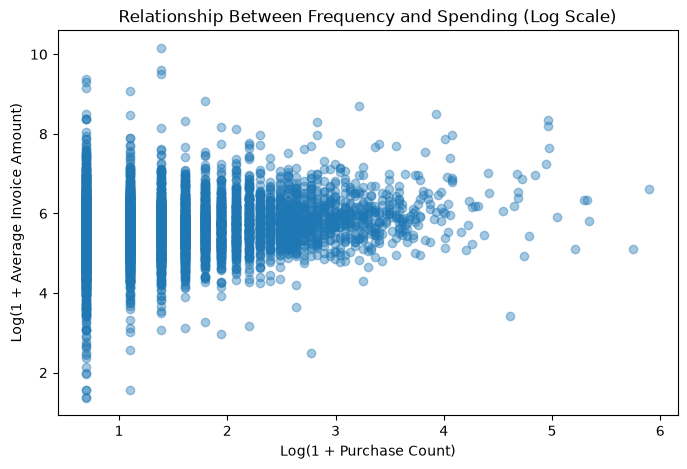

In [11]:
from scipy.stats import spearmanr

# Calculate Spearman correlation
spearman_corr, spearman_p = spearmanr(
    customer_summary["PurchaseCount"],
    customer_summary["AverageInvoiceAmount"]
)

print("Spearman correlation:", spearman_corr)
print("P-value:", spearman_p)

# Apply log transformation to reduce the influence of extreme values
customer_summary["LogPurchaseCount"] = np.log1p(
    customer_summary["PurchaseCount"]
)

customer_summary["LogAverageInvoice"] = np.log1p(
    customer_summary["AverageInvoiceAmount"]
)

# Plot the transformed variables
plt.figure(figsize=(8, 5))

plt.scatter(
    customer_summary["LogPurchaseCount"],
    customer_summary["LogAverageInvoice"],
    alpha=0.4
)

plt.xlabel("Log(1 + Purchase Count)")
plt.ylabel("Log(1 + Average Invoice Amount)")
plt.title("Relationship Between Frequency and Spending (Log Scale)")
plt.show()

In [12]:
# Import required libraries
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture

# Select the two log-transformed variables
joint_data = customer_summary[
    ["LogPurchaseCount", "LogAverageInvoice"]
].copy()

# Standardise both variables
scaler = StandardScaler()
joint_scaled = scaler.fit_transform(joint_data)

print("Original data shape:", joint_data.shape)
print("Standardised data shape:", joint_scaled.shape)

print("\nMean after standardisation:")
print(joint_scaled.mean(axis=0))

print("\nStandard deviation after standardisation:")
print(joint_scaled.std(axis=0))

Original data shape: (5824, 2)
Standardised data shape: (5824, 2)

Mean after standardisation:
[-1.43352973e-17  1.10290287e-15]

Standard deviation after standardisation:
[1. 1.]


In [13]:
# Compare Gaussian Mixture Models with 1 to 6 components

aic_values = []
bic_values = []
component_range = range(1, 7)

for k in component_range:

    gmm = GaussianMixture(
        n_components=k,
        covariance_type="full",
        random_state=42,
        n_init=10
    )

    gmm.fit(joint_scaled)

    aic_values.append(gmm.aic(joint_scaled))
    bic_values.append(gmm.bic(joint_scaled))

# Display comparison table
model_comparison = pd.DataFrame({
    "Number of Components": list(component_range),
    "AIC": aic_values,
    "BIC": bic_values
})

display(model_comparison)

# Identify the preferred number of components
best_aic = model_comparison.loc[
    model_comparison["AIC"].idxmin()
]

best_bic = model_comparison.loc[
    model_comparison["BIC"].idxmin()
]

print("Best number of components according to AIC:",
      int(best_aic["Number of Components"]))

print("Best number of components according to BIC:",
      int(best_bic["Number of Components"]))

,Number of Components,AIC,BIC
0,1,32786.717852,32820.066565
1,2,14141.950763,14215.317931
2,3,13049.331426,13162.717050
3,4,12569.923535,12723.327615
4,5,3014.219445,3207.641981
5,6,-3187.344903,-2953.903913


Best number of components according to AIC: 6
Best number of components according to BIC: 6


In [14]:
# Extend comparison from 1 to 10 components

aic_extended = []
bic_extended = []

for k in range(1, 11):

    gmm = GaussianMixture(
        n_components=k,
        covariance_type="full",
        random_state=42,
        n_init=20,
        max_iter=1000,
        reg_covar=1e-5
    )

    gmm.fit(joint_scaled)

    aic_extended.append(gmm.aic(joint_scaled))
    bic_extended.append(gmm.bic(joint_scaled))

# Create comparison table
extended_comparison = pd.DataFrame({
    "Components": range(1, 11),
    "AIC": aic_extended,
    "BIC": bic_extended
})

display(extended_comparison)

print("Best AIC components:",
      extended_comparison.loc[
          extended_comparison["AIC"].idxmin(),
          "Components"
      ])

print("Best BIC components:",
      extended_comparison.loc[
          extended_comparison["BIC"].idxmin(),
          "Components"
      ])

,Components,AIC,BIC
0,1,32786.717852,32820.066565
1,2,17928.804404,18002.171573
2,3,16839.931205,16953.316829
3,4,16361.518808,16514.922888
4,5,8970.651358,9164.073893
5,6,4257.231565,4490.672556
6,7,906.697030,1180.156476
7,8,-1367.933088,-1054.455186
8,9,-3109.384157,-2755.887800
9,10,-1655.531203,-1262.016390


Best AIC components: 9
Best BIC components: 9


In [15]:
# Fit the final Gaussian Mixture Model with 9 components

final_gmm = GaussianMixture(
    n_components=9,
    covariance_type="full",
    random_state=42,
    n_init=20,
    max_iter=1000,
    reg_covar=1e-5
)

final_gmm.fit(joint_scaled)

# Assign each customer to a segment
customer_summary["Segment"] = final_gmm.predict(joint_scaled)

# Calculate the number and percentage of customers in each segment
segment_sizes = customer_summary["Segment"].value_counts().sort_index()

segment_percentages = (
    customer_summary["Segment"].value_counts(normalize=True).sort_index() * 100
)

segment_summary = pd.DataFrame({
    "Number of Customers": segment_sizes,
    "Percentage": segment_percentages
})

display(segment_summary)

print("Total customers:", segment_summary["Number of Customers"].sum())

,Number of Customers,Percentage
Segment,,
0,611,10.491071
1,1647,28.279533
2,644,11.057692
3,757,12.997940
4,273,4.687500
5,351,6.026786
6,110,1.888736
7,491,8.430632
8,940,16.140110


Total customers: 5824


In [16]:
# Summarise purchasing behaviour within each segment

segment_characteristics = customer_summary.groupby("Segment").agg(
    CustomerCount=("CustomerID", "count"),
    AveragePurchaseCount=("PurchaseCount", "mean"),
    MedianPurchaseCount=("PurchaseCount", "median"),
    AverageInvoiceAmount=("AverageInvoiceAmount", "mean"),
    MedianInvoiceAmount=("AverageInvoiceAmount", "median"),
    AverageTotalSpending=("TotalSpending", "mean")
).round(2)

display(segment_characteristics)

,CustomerCount,AveragePurchaseCount,MedianPurchaseCount,AverageInvoiceAmount,MedianInvoiceAmount,AverageTotalSpending
Segment,,,,,,
0,611,19.45,17.0,373.70,338.50,7327.34
1,1647,1.00,1.0,348.32,233.40,348.32
2,644,3.00,3.0,339.33,282.05,1018.00
3,757,8.72,8.0,378.96,317.65,3335.54
4,273,6.00,6.0,351.79,291.95,2110.76
5,351,5.00,5.0,351.07,295.42,1755.33
6,110,59.27,46.5,1650.34,950.00,56366.77
7,491,4.00,4.0,331.82,269.20,1327.27
8,940,2.00,2.0,342.82,264.73,685.65


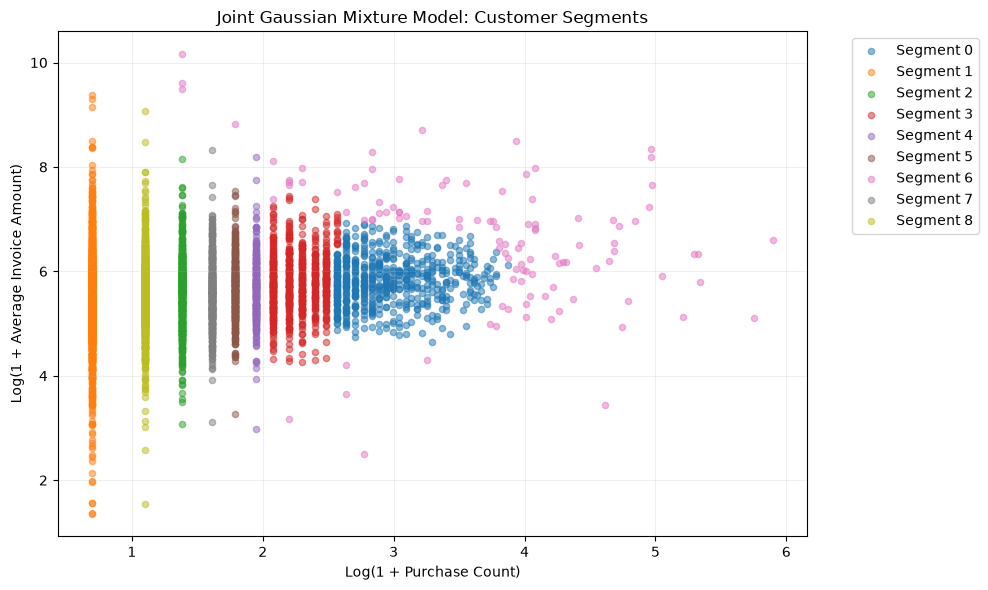

In [17]:
# Visualise the nine customer segments

plt.figure(figsize=(10, 6))

for segment in sorted(customer_summary["Segment"].unique()):

    segment_data = customer_summary[
        customer_summary["Segment"] == segment
    ]

    plt.scatter(
        segment_data["LogPurchaseCount"],
        segment_data["LogAverageInvoice"],
        label=f"Segment {segment}",
        alpha=0.5,
        s=20
    )

plt.xlabel("Log(1 + Purchase Count)")
plt.ylabel("Log(1 + Average Invoice Amount)")
plt.title("Joint Gaussian Mixture Model: Customer Segments")

plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [18]:
# Calculate membership probabilities for every customer

membership_probabilities = final_gmm.predict_proba(joint_scaled)

# Find the highest membership probability for each customer
customer_summary["AssignmentConfidence"] = (
    membership_probabilities.max(axis=1)
)

# Summarise assignment confidence
print("Average assignment confidence:",
      customer_summary["AssignmentConfidence"].mean())

print("\nConfidence summary:")
display(
    customer_summary["AssignmentConfidence"].describe()
)

# Count customers with high and low assignment confidence
high_confidence = (
    customer_summary["AssignmentConfidence"] >= 0.80
).sum()

low_confidence = (
    customer_summary["AssignmentConfidence"] < 0.60
).sum()

print("\nCustomers with confidence >= 80%:", high_confidence)
print("Customers with confidence < 60%:", low_confidence)

Average assignment confidence: 0.9526982723123267

Confidence summary:


count    5824.000000
mean        0.952698
std         0.102756
min         0.351666
25%         0.991015
50%         0.999965
75%         0.999998
max         1.000000
Name: AssignmentConfidence, dtype: float64


Customers with confidence >= 80%: 5374
Customers with confidence < 60%: 153


Customer assignment confidence:


AssignmentConfidence
Low Confidence          153
Moderate Confidence     297
High Confidence        5374
Name: count, dtype: int64

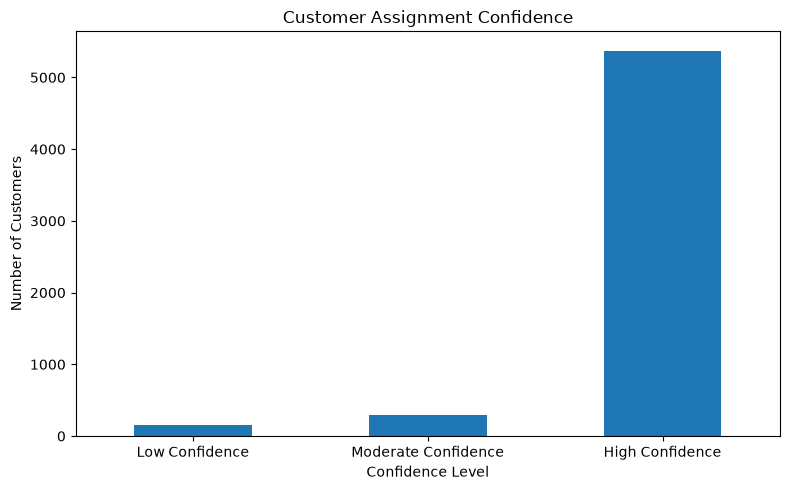

In [19]:
# Categorise customers by assignment confidence

confidence_groups = pd.cut(
    customer_summary["AssignmentConfidence"],
    bins=[0, 0.60, 0.80, 1.00],
    labels=["Low Confidence", "Moderate Confidence", "High Confidence"],
    include_lowest=True
)

confidence_counts = confidence_groups.value_counts().reindex(
    ["Low Confidence", "Moderate Confidence", "High Confidence"]
)

print("Customer assignment confidence:")
display(confidence_counts)

# Plot the results
plt.figure(figsize=(8, 5))

confidence_counts.plot(kind="bar")

plt.title("Customer Assignment Confidence")
plt.xlabel("Confidence Level")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [21]:
print("Final selected number of components:", final_gmm.n_components)

print("\nFinal model AIC:", final_gmm.aic(joint_scaled))
print("Final model BIC:", final_gmm.bic(joint_scaled))

Final selected number of components: 9

Final model AIC: -3109.3841573871196
Final model BIC: -2755.887800123664


In [22]:
[name for name in globals()
 if "gmm" in name.lower() or "component" in name.lower()]

['component_range', 'gmm', 'final_gmm']

In [23]:
print("Final number of components:", final_gmm.n_components)

print("Final model AIC:", final_gmm.aic(joint_scaled))

print("Final model BIC:", final_gmm.bic(joint_scaled))

Final number of components: 9


NameError: name 'X_scaled' is not defined

In [ ]:
[name for name in globals()
 if name.startswith("X") or "scaled" in name.lower()
 or "standard" in name.lower()]

In [ ]:
print("Final number of components:", final_gmm.n_components)

print("Final model AIC:", final_gmm.aic(joint_scaled))

print("Final model BIC:", final_gmm.bic(joint_scaled))

# 7. Conditional Expectation and Law of Total Expectation

In [ ]:
# Conditional Expectation of Customer Spending

conditional_summary = customer_summary.groupby("Segment").agg(
    CustomerCount=("CustomerID", "count"),
    ExpectedTotalSpending=("TotalSpending", "mean"),
    ExpectedPurchaseCount=("PurchaseCount", "mean"),
    ExpectedAverageInvoice=("AverageInvoiceAmount", "mean")
).reset_index()

conditional_summary["SegmentProbability"] = (
    conditional_summary["CustomerCount"] / len(customer_summary)
)

display(conditional_summary.round(2))

In [ ]:
# Verification of Law of Total Expectation

overall_mean_spending = customer_summary["TotalSpending"].mean()

weighted_conditional_mean = (
    conditional_summary["SegmentProbability"] *
    conditional_summary["ExpectedTotalSpending"]
).sum()

print("Overall Mean Spending:", round(overall_mean_spending, 2))
print("Weighted Conditional Mean:", round(weighted_conditional_mean, 2))

print("Difference:", round(
    overall_mean_spending - weighted_conditional_mean, 10
))

In [ ]:
# Define a linear combination of two customer variables

a = 2
b = 3

customer_summary["LinearCombination"] = (
    a * customer_summary["TotalSpending"] +
    b * customer_summary["PurchaseCount"]
)

print("Linear combination created successfully.")
display(customer_summary[
    ["CustomerID", "Segment", "TotalSpending",
     "PurchaseCount", "LinearCombination"]
].head())

In [ ]:
# Verify Linearity of Conditional Expectation

linearity_summary = customer_summary.groupby("Segment").agg(
    ActualConditionalMean=("LinearCombination", "mean"),
    MeanSpending=("TotalSpending", "mean"),
    MeanPurchases=("PurchaseCount", "mean")
).reset_index()

linearity_summary["ExpectedUsingLinearity"] = (
    a * linearity_summary["MeanSpending"] +
    b * linearity_summary["MeanPurchases"]
)

linearity_summary["Difference"] = (
    linearity_summary["ActualConditionalMean"] -
    linearity_summary["ExpectedUsingLinearity"]
)

display(linearity_summary.round(6))